# picomake - activations_gradients

In [20]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [21]:
words = open("names.txt", "r").read().split()
words[:3]

# build vocabulary

stoi = {}
stoi['.'] = 0
vocab = sorted(list(set(letters for word in words for letters in word)))
for i, ch in enumerate(vocab, start = 1):
    stoi[ch] = i
stoi

{'.': 0,
 'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26}

In [22]:
# build out dataset
def build_dataset(words):
    context_size = 3
    X = []
    Y = []

    for w in words:
        context = [0]*context_size

        for i in w+'.':
            ix = stoi[i]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context [1:] + [ix]


    X = torch.tensor(X) # X stores the context of one training example in chunk of context size (stoi)
    Y = torch.tensor(Y) # Y stores the stoi value of each char in the word
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

# let us create an embedding matrix where every character 
# gets a 2 dimensional embedding using the awesome pytorch indexing
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,2), generator=g)
emb = C[Xtr] # torch.Size([182625, 3, 2])

In [23]:
# neural network

# prepare out training data

W1 = torch.randn((30, 300), generator=g)
b1 = torch.randn(300, generator=g)
C = torch.randn((27,10), generator=g)
W2 = torch.randn((300, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = (C, W1, b1, W2, b2)

print(f"number of parameters = {sum(p.nelement() for p in parameters)}")

for p in parameters:
    p.requires_grad = True

# finding a good lr
lre = torch.linspace(-3, 0, 30000)
lre = 10**lre




number of parameters = 17697


In [24]:
# =================================FULL TRAINING LOOP================================#

losses = []
lrs = []
steps = []

for i in range(500000):

    # batch gradient descent

    ix = torch.randint(0, Xtr.shape[0], (64, ))

    # forward pass
    emb = C[Xtr[ix]]

    h1 = emb.view(-1, 30) @ W1 + b1 # -1 means any rows
    h1 = torch.tanh(h1)

    logits = h1@W2 + b2

    loss = F.cross_entropy(logits, Ytr[ix])

    # backward pass
    # set grad = None
    for p in parameters:
        p.grad = None

    loss.backward()

    # optimise
    # lr = lre[i]
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data -= lr * p.grad

    #track
    losses.append(loss.log10().item())
    lrs.append(lr)
    steps.append(i)
    

print(loss.item())

1.8576260805130005


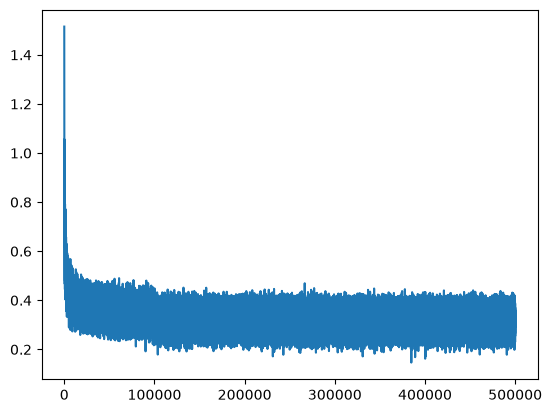

In [25]:
plt.plot(steps, losses)

In [26]:
# validation tests

emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
losstrain = F.cross_entropy(logits, Ytr)

emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
lossval = F.cross_entropy(logits, Ydev)

# if nearly same, our network is underfitting. scaling up the model.
print(f"training loss - {losstrain}\n validation loss - {lossval}")


training loss - 2.0847432613372803
 validation loss - 2.134389638900757
